# A principal component entropy metric for assessing global synchronicity in EEG signals

In [ ]:
# Main imports
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Matplot lib settings
plt.rcParams.update({
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.linestyle': '--',
})

## Principal component (PC) entropy

In [ ]:
def pc_entropy(x: np.ndarray):
    """ 
    Compute the PC-entropy for a matrix.  
    
    Args:
        x (np.ndarray): a matrix (..., N , M ) where N is the number of samples and M is the number of channels

    Return:
        The PC-entropy value. For matrices with more than two dimensions the PC-entropy will be iterated along the other dimensions.

    """
    channels_index = -1  
    samples_index = -2
    samples_n = x.shape[samples_index] # N
    channels_n = x.shape[channels_index] # M

    # computing covariance matrixes
    c = x - x.mean(axis=samples_index, keepdims=True)
    c_t = np.swapaxes(c, samples_index, channels_index)
    cov =  c_t @ c / (samples_n - 1)

    assert cov.shape[-2:] == (channels_n, channels_n)

    # compute the eigenvalues
    lam = np.linalg.eigvalsh(cov)
    lam = np.clip(lam, 0, None) # Clipping minimum value to avoid numerical errors

    # normalize the eigenvalues
    p = lam / lam.sum(axis=-1, keepdims=True)

    plogp = np.where(p > 0, p * np.log2(np.where(p > 0, p, 1)), 0.0)

    return  -plogp.sum(axis=-1) / np.log2(channels_n)

## Kuramoto model

In [ ]:
from scipy.integrate import solve_ivp
from joblib import Parallel, delayed
from typing import NamedTuple

# This is the ODE equation from the paper
def rhs(t, th, omega, G, K, M):
        # outer compute the matrix of differences
        coupling = (G * np.sin(-np.subtract.outer(th, th))).sum(axis=1)
        return omega + (K / M) * coupling

# this computes R
def order_parameter(th, axis=0):
    return np.abs(np.exp(1j * th).sum(axis=axis)) / th.shape[0]


class KuramotoResult(NamedTuple):
    order_parameter: float
    pc_entropy: float
    pc_entropy_denorm: float

def sample_from_kuramoto_model(
    coupling_constant: float, 
    number_of_oscillators: int, 
    fs: float, 
    number_of_samples: int, 
    transition_time: float =100, 
    seed=42
) -> np.ndarray:
    # setting random seed
    rng = np.random.default_rng(seed)

    # frequencies
    omegas = rng.normal(1, 0.25, number_of_oscillators) # rad/s
    # weights
    G = rng.normal(1, 0.25, (number_of_oscillators, number_of_oscillators))

    t_eval = transition_time + np.arange(number_of_samples) / fs
    th0 = rng.normal(0, np.pi/2, number_of_oscillators)
    sol = solve_ivp(rhs, (0, t_eval[-1]), th0, t_eval=t_eval,
                    args=(omegas, G, coupling_constant, number_of_oscillators), rtol=1e-6, atol=1e-8)
    assert sol.y.shape == (number_of_oscillators, number_of_samples) # the solution should be n_samples for M oscillators

    # raise an error if numerical integration fails
    if not sol.success:
        raise RuntimeError(sol.message)

    return sol.y

In [ ]:
from matplotlib.animation import FuncAnimation, PillowWriter

fs = 10
N = 1024
M = 5
transition_time = 100

def f(k):
    return sample_from_kuramoto_model(
        number_of_oscillators=M,
        coupling_constant=k,
        fs=fs,
        number_of_samples=N,
        transition_time=transition_time
    )

t = np.arange(0, N) / fs + transition_time
k_count = 100
ks = np.linspace(0, 1, k_count)

thetas = []

for k in ks:
    thetas.append(f(k))


In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
lines = [ax.plot([], [], lw=1.5)[0] for _ in range(M)]
title = ax.set_title("")

ax.set_xlim(100, 120)
ax.set_ylim(-1.1, 1.1)
ax.set_xlabel("Time (s)")

def update(frame):
    i, k = frame
    theta = thetas[i]
    for line, osc in zip(lines, np.sin(theta)):
        line.set_data(t, osc)
    title.set_text(f"K = {k:.2f}, R = {order_parameter(theta).mean():.2f}")
    return (*lines, title)


parameters = list(enumerate(ks))
anim = FuncAnimation(fig, update, frames=parameters, interval=100)
anim.save("kuramoto_model_animation.gif", writer=PillowWriter(fps=20))
plt.close(fig)

In [ ]:

def job(
    coupling_constant: float, 
    number_of_oscillators: int, 
    fs: float, 
    number_of_samples: int, 
    transition_time: float, 
    seed: int
) -> KuramotoResult:
    y = sample_from_kuramoto_model(
        coupling_constant=coupling_constant,
        number_of_oscillators=number_of_oscillators,
        fs=fs,
        number_of_samples=number_of_samples,
        transition_time=transition_time,
        seed=seed
    )

    pc_entropy_ = pc_entropy(np.sin(y.T))
    pc_entropy_denorm = pc_entropy_ * np.log2(number_of_oscillators)  
    # order parameter is computed along axis 0 which is the number of oscillators (as in the paper)
    # so we are left with an order parameter means along the oscillator for each sample.
    # To asses the sinchronicity of the system we compute the mean between them
    order_parameters = order_parameter(y, axis=0)

    return KuramotoResult(order_parameters.mean(), pc_entropy_, pc_entropy_denorm)

class KuramotoRunsResult(NamedTuple):
    coupling_constants: np.ndarray
    order_parameters: np.ndarray
    order_parameters_sem: np.ndarray
    pces: np.ndarray
    pces_sem: np.ndarray
    pces_denorm: np.ndarray
    pces_denorm_sem: np.ndarray

def kuramoto_runs(
        number_of_oscillators: int, 
        coupling_constant_max: float, 
        coupling_constant_count: int, 
        fs: float, 
        number_of_samples: int,
        transition_time=100, 
        number_of_runs=50,
        seed=42
    ) -> KuramotoRunsResult:
    """Run a specified number of runs of a Kuramoto experiment with different values of the coupling constants. Returns results for each value of the coupling constant averaged between the runs

    Args:
        number_of_oscillators (int): the number of oscillators.
        coupling_constant_max (float): the maximum value of the coupling constant for which Kuramoto is run.
        coupling_constant_count (int): the number of coupling constant. The resulting coupling constants will be the one in the range between 0 and the maximu value with step maximum divided by this parameter.
        fs (float): the sampling frequency used to sample from the Kuramoto model.
        number_of_samples (int): the number of samples to be taken.

    Keyword Args:
        transition_time (default=100): the instant of time from which the samples are taken
        number_of_runs (default=50): the number of runs.
        seed (default=42): the seed, used for reproducibility.
    """
    ks = np.linspace(0, coupling_constant_max, coupling_constant_count)

    out = Parallel(n_jobs=-1)(
        delayed(job)(K, number_of_oscillators, fs, number_of_samples, transition_time, [seed, i, r])
        for i, K in enumerate(ks) for r in range(number_of_runs)
    )

    out = np.array(out).reshape(coupling_constant_count, number_of_runs, 3)
    r, pce, pce_dn = out[..., 0], out[..., 1], out[..., 2]

    sem = lambda a: a.std(axis=1, ddof=1) / np.sqrt(number_of_runs)
    return KuramotoRunsResult(
        ks, 
        r.mean(axis=1), 
        sem(r), 
        pce.mean(axis=1), 
        sem(pce), 
        pce_dn.mean(axis=1), 
        sem(pce_dn)
    )

In [ ]:
# Fixed window length experiments
number_of_oscillators = 30
coupling_constant_max = 0.8
coupling_constant_step = 20
window_length = 819.2

fss = [0.625, 1.25, 2.5]

kuramotos_fixed_window_length = {fs : kuramoto_runs(
    number_of_oscillators=number_of_oscillators,
    coupling_constant_max=coupling_constant_max,
    coupling_constant_count= coupling_constant_step,
    fs=fs,
    number_of_samples=int(window_length*fs)
) for fs in fss}

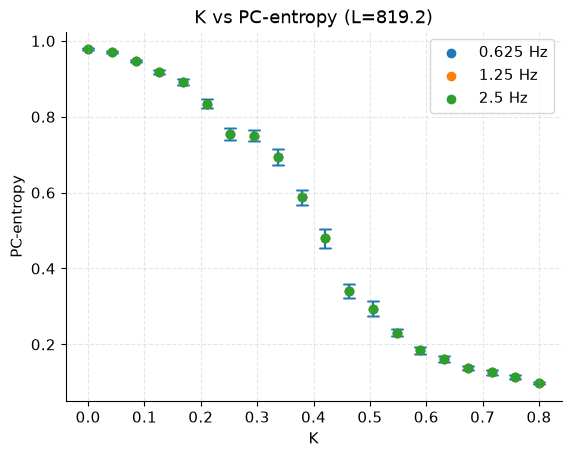

In [ ]:
for fs, kuramoto in kuramotos_fixed_window_length.items():
    ks, rs, _ , pces, errs, _, _ = kuramoto
    plt.errorbar(ks, pces, yerr=errs, fmt='none', capsize=4, zorder=1)
    plt.scatter(ks, pces, label=f'{fs:.4g} Hz')

plt.legend()
plt.title('K vs PC-entropy (L=819.2)')
plt.xlabel('K')
plt.ylabel('PC-entropy')
plt.show()

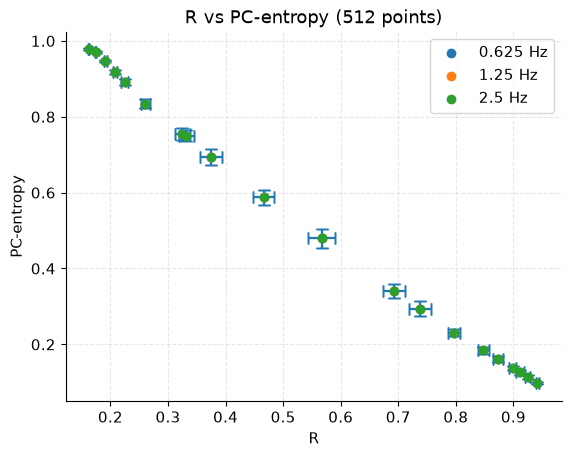

In [ ]:
for fs, kuramoto in kuramotos_fixed_window_length.items():
    k_, rs, rs_sem, pces, pces_sem, _, _ = kuramoto
    plt.errorbar(rs, pces, xerr=rs_sem, yerr=pces_sem, fmt='none', capsize=4, zorder=1)
    plt.scatter(rs, pces, label=f'{fs:.4g} Hz')

plt.legend()
plt.title('R vs PC-entropy (512 points)')
plt.xlabel('R')
plt.ylabel('PC-entropy')
plt.show()

In [ ]:
# Fixed samples experiments
number_of_oscillators = 30
coupling_constant_max = 0.8
coupling_constant_step = 20
number_of_samples = 512

fss = [0.625, 1.25, 2.5]

kuramotos_fixed_sampling_n = {fs : kuramoto_runs(
    number_of_oscillators=number_of_oscillators,
    coupling_constant_max=coupling_constant_max,
    coupling_constant_count=coupling_constant_step,
    fs=fs,
    number_of_samples=number_of_samples
) for fs in fss}

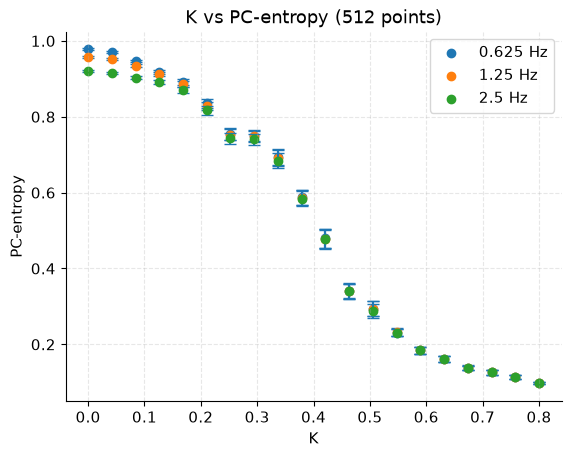

In [ ]:
for fs, kuramoto in kuramotos_fixed_sampling_n.items():
    ks, rs, order_apr, pces, errs, _, _ = kuramoto
    plt.errorbar(ks, pces, yerr=errs, fmt='none', capsize=4, zorder=1)
    plt.scatter(ks, pces, label=f'{fs:.4g} Hz')

plt.legend()
plt.title('K vs PC-entropy (512 points)')
plt.xlabel('K')
plt.ylabel('PC-entropy')
plt.show()

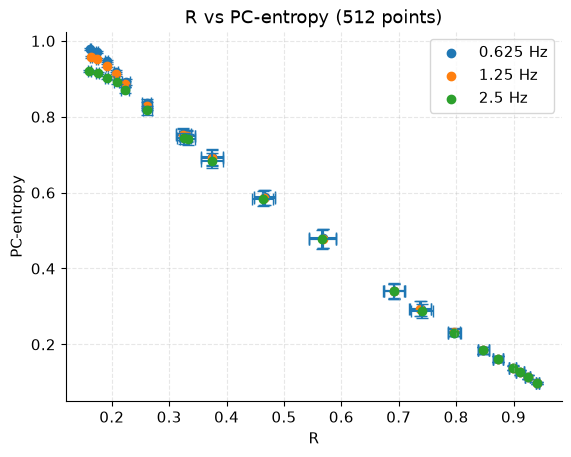

In [ ]:
for fs, kuramoto in kuramotos_fixed_sampling_n.items():
    k_, rs, rs_sem, pces, pces_sem, _, _ = kuramoto
    plt.errorbar(rs, pces, xerr=rs_sem, yerr=pces_sem, fmt='none', capsize=4, zorder=1)
    plt.scatter(rs, pces, label=f'{fs:.4g} Hz')

plt.legend()
plt.title('R vs PC-entropy (512 points)')
plt.xlabel('R')
plt.ylabel('PC-entropy')
plt.show()

In [ ]:
fs = 0.625
kuramoto30 = kuramotos_fixed_sampling_n[fs]

kuramoto20 = kuramoto_runs(
    number_of_oscillators=20,
    coupling_constant_max=0.8,
    coupling_constant_count=20,
    fs=fs,
    number_of_samples=512,
)

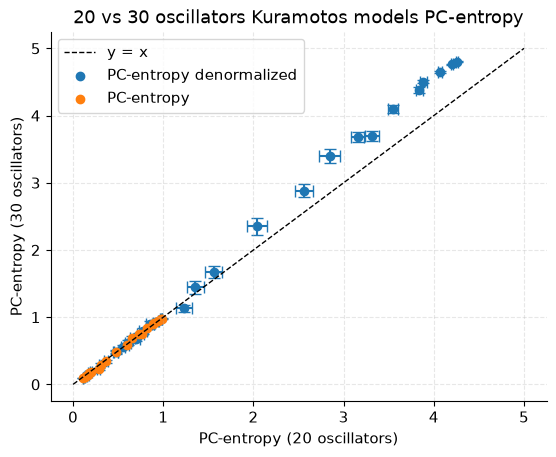

In [ ]:
lim = [0, 5]
plt.plot(lim, lim, "k--", lw=1, label="y = x")

plt.scatter(x=kuramoto20.pces_denorm, y=kuramoto30.pces_denorm, label='PC-entropy denormalized')
plt.errorbar(
    x=kuramoto20.pces_denorm, 
    y=kuramoto30.pces_denorm, 
    xerr=kuramoto20.pces_denorm_sem, 
    yerr=kuramoto30.pces_denorm_sem, 
    fmt='none', 
    capsize=4, 
    zorder=1
)

plt.scatter(x=kuramoto20.pces, y=kuramoto30.pces, label='PC-entropy')
plt.errorbar(
    x=kuramoto20.pces, 
    y=kuramoto30.pces, 
    xerr=kuramoto20.pces_sem, 
    yerr=kuramoto30.pces_sem, 
    fmt='none', 
    capsize=4, 
    zorder=0
)

plt.title('20 vs 30 oscillators Kuramotos models PC-entropy')
plt.ylabel('PC-entropy (30 oscillators)')
plt.xlabel('PC-entropy (20 oscillators)')
plt.legend()
plt.show()

## Analysis on the arithmetic task dataset

In [ ]:
import physionet
from pathlib import Path

DATA_DIR = Path("eegmat-1.0.0")

# Download the database if not already present
if not DATA_DIR.exists():
    physionet.download("eegmat", version="1.0.0", output_dir=str(DATA_DIR))

In [ ]:
info = physionet.load("eegmat", table="subject-info", version="1.0.0")
info

,Subject,Age,Gender,Recording year,Number of subtractions,Count quality
0,Subject00,21,F,2011,9.70,0
1,Subject01,18,F,2011,29.35,1
2,Subject02,19,F,2012,12.88,1
3,Subject03,17,F,2010,31.00,1
4,Subject04,17,F,2010,8.60,0
5,Subject05,16,F,2010,20.71,1
6,Subject06,18,M,2011,4.35,0
7,Subject07,18,F,2012,13.38,1
8,Subject08,26,M,2011,18.24,1
9,Subject09,16,F,2010,7.00,0


In [ ]:
from pathlib import Path
from pyedflib import highlevel
import pandas as pd

DATA_DIR = Path("eegmat-1.0.0")

def load_subject_edf(subject_number: int, condition: int):
    DATA_DIR = Path("eegmat-1.0.0")

    if not 0 <= subject_number <= 35:
        raise RuntimeError('Subject number must be between 0 and 35 (included)')

    if condition != 1 and condition != 2:
        raise RuntimeError('Condition must be either 1 (rest) or 2 (arithmetic task)')

    signals, signal_headers, header = highlevel.read_edf(str(DATA_DIR / f'Subject{subject_number:02d}_{condition}.edf'))
    fs = signal_headers[0]["sample_frequency"]
    return signals, fs

def build_table(condition: str | int) -> pd.DataFrame:
    valid_conditions = {'rest': 1, 'arithmetic task': 2}
    
    if isinstance(condition, str) is str and condition not in valid_conditions.keys():
        raise RuntimeError("Condition must be either 'rest' or 'arithmetic task'")

    if isinstance(condition, str): condition = valid_conditions[condition]

    rows = []
    for i, subject in enumerate(info.Subject):
        signals, fs = load_subject_edf(subject_number=int(i), condition=condition)
        rows.append({'Subject': subject, 'fs':fs, 'eeg': signals[:19]})

    return info.merge(pd.DataFrame(rows), on='Subject')

In [ ]:
eegs_rest_df = build_table('rest')
eegs_rest_df.head()

,Subject,Age,Gender,Recording year,Number of subtractions,Count quality,fs,eeg
0,Subject00,21,F,2011,9.70,0,500.0,"[[-3.647938, -4.236482, -4.954218, -5.703854, ..."
1,Subject01,18,F,2011,29.35,1,500.0,"[[-6.347912, -5.884709, -5.160955, -4.313504, ..."
2,Subject02,19,F,2012,12.88,1,500.0,"[[-1.489817, -3.51847, -5.22801, -6.166703, -6..."
3,Subject03,17,F,2010,31.00,1,500.0,"[[5.887305, 4.211407, 2.132053, -0.079719, -2...."
4,Subject04,17,F,2010,8.60,0,500.0,"[[-6.645441, -6.435402, -6.276706, -6.234698, ..."


In [ ]:
eegs_arithmetic_df = build_table('arithmetic task')
eegs_arithmetic_df.head()

,Subject,Age,Gender,Recording year,Number of subtractions,Count quality,fs,eeg
0,Subject00,21,F,2011,9.70,0,500.0,"[[4.476049, 1.208021, -2.546008, -6.187074, -9..."
1,Subject01,18,F,2011,29.35,1,500.0,"[[13.990337, 12.876663, 11.885061, 11.246529, ..."
2,Subject02,19,F,2012,12.88,1,500.0,"[[3.52582, 2.5774, 0.958405, -0.975839, -2.584..."
3,Subject03,17,F,2010,31.00,1,500.0,"[[5.035679, 3.356242, 0.928292, -2.09721, -5.3..."
4,Subject04,17,F,2010,8.60,0,500.0,"[[1.172364, 1.752832, 2.449393, 3.077459, 3.35..."


In [ ]:
eegs_rest_df['eeg'].apply(np.shape).value_counts()

eeg
(19, 91000)    33
(19, 85000)     1
(19, 94000)     1
(19, 40000)     1
Name: count, dtype: int64

In [ ]:
eegs_arithmetic_df['eeg'].apply(np.shape).value_counts()

eeg
(19, 31000)    36
Name: count, dtype: int64

In [ ]:
# check of the sampling frequency
EEG_FS = 500
eegs_rest_df['fs'].value_counts(), eegs_arithmetic_df['fs'].value_counts()

(fs
 500.0    36
 Name: count, dtype: int64,
 fs
 500.0    36
 Name: count, dtype: int64)

In [ ]:
def get_matrix(df: pd.DataFrame, seconds=60, fs=500) -> np.ndarray:
    N = seconds * fs
    array = np.stack([x[: , :N] for x in df['eeg']])
    return np.swapaxes(array, -1, -2)

In [ ]:
eegs_rest = get_matrix(eegs_rest_df)
eegs_arithmetic = get_matrix(eegs_arithmetic_df)

assert eegs_rest.shape == eegs_arithmetic.shape and eegs_arithmetic.shape == (36, 30000, 19)

In [ ]:
# Filter design

from scipy.signal import firwin

def fir_bandpass(l_freq, h_freq, fs, l_trans, h_trans, window='hamming'):
    constants = {
        'rectangular': 0.9,
        'bartlett': 2.9,
        'hann': 3.1,
        'hamming': 3.3,
        'blackman': 5.5
    }

    if window not in constants.keys():
        raise RuntimeError(f'Invalid window name {window} select one within {constants.keys()}')
    
    # Δω = 2πf / fs
    # Δω = cπ / L
    # 2πfs / f = cπ / L
    # L = 0.5c f / fs
    
    c = constants[window]

    L_hp = int(np.ceil(c*fs/l_trans)) | 1
    L_lp = int(np.ceil(c*fs/h_trans)) | 1

    #  ωs - ωp: transition band width
    # (ωs + ωp) / 2: cutoff frequency

    hp = firwin(
        numtaps=L_hp,
        cutoff=l_freq - l_trans/2, # (l_freq - l_trans + l_freq)/2  
        pass_zero=False,
        fs=fs,
        window=window
    )

    lp = firwin(
            numtaps=L_lp,                   
            cutoff=h_freq + h_trans/2, #(h_freq + h_freq + h_trans)/2
            pass_zero=True,
            fs=fs,
            window=window
        )

    return np.convolve(np.asarray(hp), np.asarray(lp))

In [ ]:
# filters
WINDOW = 'hamming'
EEG_WAVES = ('delta', 'theta', 'alpha', 'beta', 'gamma')

delta, theta, alpha, beta, gamma = EEG_WAVES

class WaveFIRConfig(NamedTuple):
    l_freq: float
    h_freq: float
    l_trans: float
    h_trans: float

wave_fir_configs = {
    delta: WaveFIRConfig(
        l_freq=1,
        h_freq=4,
        l_trans=1,
        h_trans=2
    ),
    theta: WaveFIRConfig(
        l_freq=4,
        h_freq=8,
        l_trans=2,
        h_trans=2
    ),
    alpha: WaveFIRConfig(
        l_freq=8,
        h_freq=13,
        l_trans=2,
        h_trans=3.25
    ),
    beta: WaveFIRConfig(
        l_freq=13,
        h_freq=30,
        l_trans=3.25,
        h_trans=7.5
    ),
    gamma: WaveFIRConfig(
        l_freq=30,
        h_freq=45,
        l_trans=7.5,
        h_trans=3
    )
}


waves_filters = {
    wave: fir_bandpass(
    l_freq=config.l_freq,
    h_freq=config.h_freq,
    fs=EEG_FS,
    l_trans=config.l_trans,
    h_trans=config.h_trans,
    window=WINDOW,    
    ) for wave, config in wave_fir_configs.items()
}

In [ ]:
from scipy.signal import filtfilt
from typing import Dict

def filter_wave(x, filter):
    return filtfilt(filter, [1.0], x, axis=-2)

def filter_eeg_by_wave_bands(eeg: np.ndarray) -> Dict[str, np.ndarray]:
    return {
        wave: filter_wave(eeg, f)
        for wave, f in waves_filters.items()
    }

In [ ]:
eegs_rest_waves = filter_eeg_by_wave_bands(eegs_rest)
eegs_arithmetic_waves = filter_eeg_by_wave_bands(eegs_arithmetic)

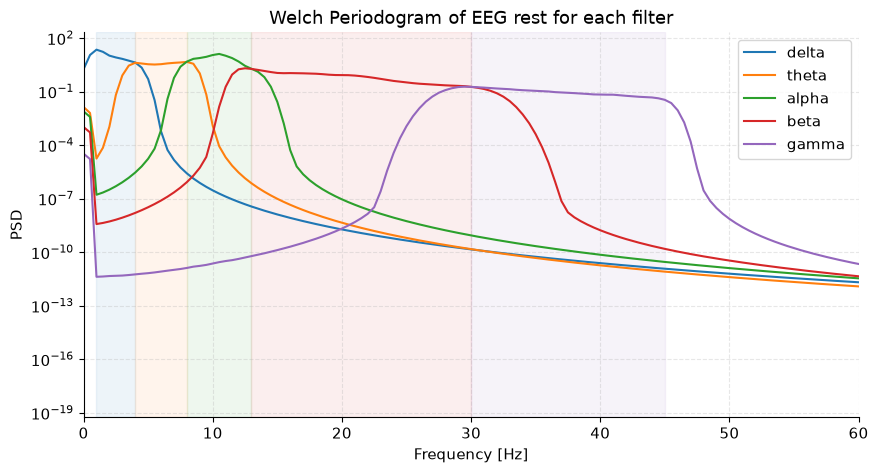

In [ ]:
from scipy.signal import welch
fig, ax = plt.subplots(figsize=(10, 5))
for name, cfg in wave_fir_configs.items():
    fs = 500
    f, P = welch(eegs_rest_waves[name], fs=fs, nperseg=1000, axis=-2)
    line, = ax.semilogy(f, P.mean(axis=(0, -1)), label=name)
    ax.axvspan(cfg.l_freq, cfg.h_freq, color=line.get_color(), alpha=0.08)

ax.set_xlim(0, 60)
ax.set_xlabel("Frequency [Hz]"); 
ax.set_ylabel("PSD")
ax.set_title('Welch Periodogram of EEG rest for each filter')
ax.legend() 
plt.show()

In [ ]:
def pc_entropy_sliding_window(x: np.ndarray, samples_count=5, window_length=10):
    avg5 = np.lib.stride_tricks.sliding_window_view(x, axis=1, window_shape=samples_count)[:, ::samples_count, :].mean(axis=-1)

    fs=100
    w=window_length*fs
    avg10 = avg5.reshape(x.shape[0], -1, w, x.shape[-1])
    pce6 = pc_entropy(avg10)
    return pce6.mean(axis=-1)

In [ ]:
pce_rest_waves = {
    wave: pc_entropy_sliding_window(eeg) 
    for wave, eeg in eegs_rest_waves.items()
}

pce_arithmetic_waves = {
    wave: pc_entropy_sliding_window(eeg) 
    for wave, eeg in eegs_arithmetic_waves.items()
}

In [ ]:
from typing import Dict, Tuple

good_counters = info['Count quality'].to_numpy(dtype=bool)
bad_counters = ~good_counters

def split_poor_good(x: Dict[str, np.ndarray], good_counters: np.ndarray) -> Tuple[Dict[str, np.ndarray], Dict[str, np.ndarray]]:
    
    x_gc_waves = {
        wave: pce[good_counters]
        for wave, pce in x.items() 
    }

    x_pc_waves = {
        wave: pce[bad_counters]
        for wave, pce in x.items()
    }

    return x_gc_waves, x_pc_waves

pce_rest_gc_waves, pce_rest_pc_waves = split_poor_good(x=pce_rest_waves, good_counters=good_counters)
pce_arithmetic_gc_waves, pce_arithmetic_pc_waves = split_poor_good(x=pce_arithmetic_waves, good_counters=good_counters)

In [ ]:
from scipy.stats import wilcoxon, false_discovery_control

def measure_differences(x, y, keys, threshold=0.05):
    pvals = np.array([wilcoxon(x[wave], y[wave]).pvalue for wave in keys])
    qvals = false_discovery_control(pvals)

    return {(k, p, q) for k, p, q in zip(keys, pvals, qvals) if q <= threshold}

In [ ]:
from typing import Set
def print_significance(significance_labels: Set[Tuple[str, float, float]]) -> None:
    print('Significant differences (q ≤ 0.05)')
    print('-----------------------')
    for significance_label in significance_labels:
        label, p, q = significance_label
        print(f'{label:6s}: p={p:.4f}, q={q:.4f}')
    print()


In [ ]:
significants_gc = measure_differences(pce_rest_gc_waves, pce_arithmetic_gc_waves, EEG_WAVES)
significants_pc = measure_differences(pce_rest_pc_waves, pce_arithmetic_pc_waves, EEG_WAVES)

print_significance(significants_gc)
print_significance(significants_pc)

Significant differences (q ≤ 0.05)
-----------------------
alpha : p=0.0016, q=0.0040
beta  : p=0.0007, q=0.0037

Significant differences (q ≤ 0.05)
-----------------------



In [ ]:
def plot_boxplots(pce_rest, pce_task, title='', significant=None):
    keys = list(pce_rest.keys())
    x = np.arange(len(keys))
    width = 0.35

    fig, ax = plt.subplots(figsize=(10, 5))
    bp_a = ax.boxplot(list(pce_rest.values()),
                      positions=x - width/2, widths=0.3,
                      patch_artist=True, label='Rest', medianprops=dict(color='red'))
    bp_b = ax.boxplot(list(pce_task.values()),
                      positions=x + width/2, widths=0.3,
                      patch_artist=True, label='Math', medianprops=dict(color='red'))


    for box in bp_a['boxes']:
        box.set_facecolor('royalblue')
        box.set_alpha(0.75)
    for box in bp_b['boxes']:
        box.set_facecolor('coral')
        box.set_alpha(0.75)

    if significant:
        for n, (wave, p, q) in enumerate(significant):
            i = keys.index(wave)
            ax.axvspan(x[i] - 0.45, x[i] + 0.45,
                       color='gold', alpha=0.2, zorder=0,
                       label='q ≤ 0.05' if n == 0 else None)

    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(keys)
    ax.legend()

    ax.set_ylabel('PC-entropy')

    plt.show()

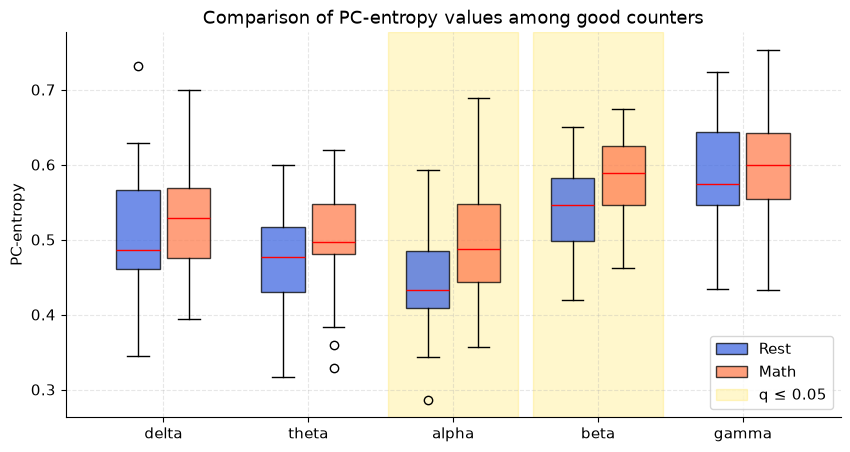

In [ ]:
plot_boxplots(
    pce_rest=pce_rest_gc_waves, 
    pce_task=pce_arithmetic_gc_waves, 
    title='Comparison of PC-entropy values among good counters', 
    significant=measure_differences(pce_rest_gc_waves, pce_arithmetic_gc_waves, EEG_WAVES)
    )

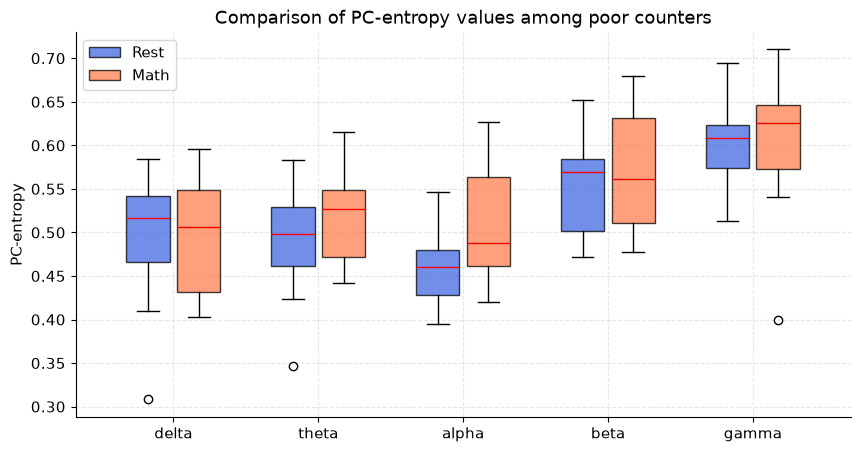

In [ ]:
plot_boxplots(
    pce_rest=pce_rest_pc_waves, 
    pce_task=pce_arithmetic_pc_waves, 
    title='Comparison of PC-entropy values among poor counters',
    significant=significants_pc
    )

In [ ]:
pce_rest_waves_7 = {
    wave: pc_entropy_sliding_window(filter_wave(eegs_rest[..., :7], f))
    for wave, f in waves_filters.items()
}

pce_arithmetic_waves_7 = {
    wave: pc_entropy_sliding_window(filter_wave(eegs_arithmetic[..., :7], f))
    for wave, f in waves_filters.items()
}

In [ ]:
pce_rest_gc_waves_7, pce_rest_pc_waves_7 = split_poor_good(x=pce_rest_waves_7, good_counters=good_counters)
pce_math_gc_waves_7, pce_math_pc_waves_7 = split_poor_good(x=pce_arithmetic_waves_7, good_counters=good_counters)

In [ ]:
significants_gc_7 = measure_differences(pce_rest_gc_waves_7, pce_math_gc_waves_7, EEG_WAVES)
significants_pc_7 = measure_differences(pce_rest_pc_waves_7, pce_math_pc_waves_7, EEG_WAVES)

print_significance(significants_gc_7)
print_significance(significants_pc_7)

Significant differences (q ≤ 0.05)
-----------------------
beta  : p=0.0000, q=0.0001
theta : p=0.0140, q=0.0233
alpha : p=0.0029, q=0.0073

Significant differences (q ≤ 0.05)
-----------------------
alpha : p=0.0059, q=0.0146
theta : p=0.0020, q=0.0098
beta  : p=0.0273, q=0.0456



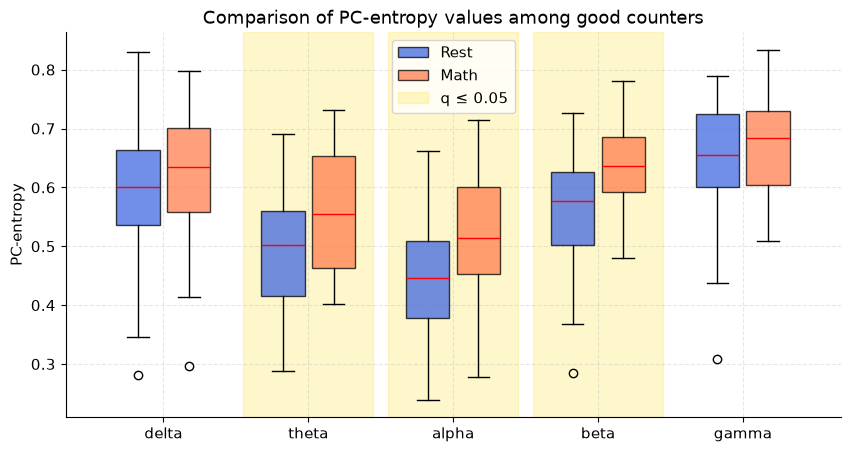

In [ ]:
plot_boxplots(
    pce_rest=pce_rest_gc_waves_7, 
    pce_task=pce_math_gc_waves_7, 
    title='Comparison of PC-entropy values among good counters',
    significant=significants_gc_7
    )

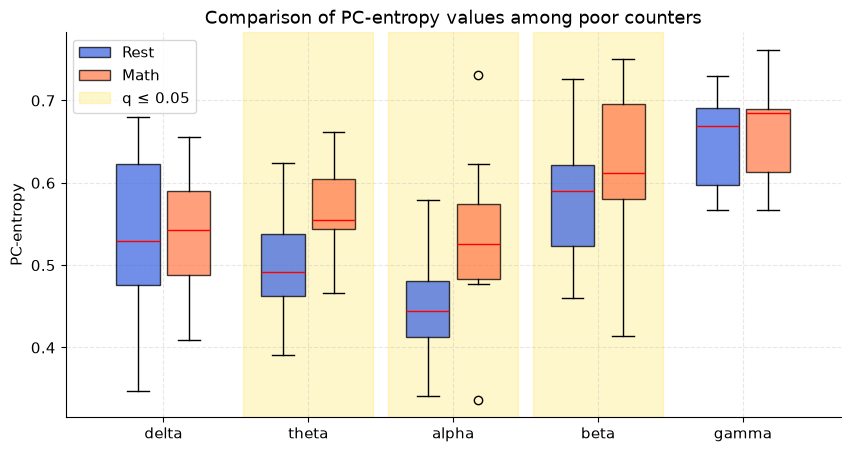

In [ ]:
plot_boxplots(
    pce_rest=pce_rest_pc_waves_7, 
    pce_task=pce_math_pc_waves_7, 
    title='Comparison of PC-entropy values among poor counters',
    significant=significants_pc_7
    )